In [ ]:
# ============================================================
# GM(1,1) ROLLING MODEL
# Ventana móvil de 4 observaciones
# Series: Sensor, Estación y Sensor corregido (desde Excel)
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files


# ============================================================
# 1. SUBIR Y LEER EL EXCEL
# ============================================================

subido = files.upload()
nombre_archivo = list(subido.keys())[0]
df = pd.read_excel(nombre_archivo)
print(df.columns.tolist())

col_fecha     = "Fecha"
col_sensor    = "Sensor"
col_ref       = "Estacion"
col_corregido = "Sensor_corregido"

Saving regresion_lineal_simple_datos_corregidos.xlsx to regresion_lineal_simple_datos_corregidos.xlsx
['Fecha', 'Estacion', 'Sensor', 'Sensor_corregido']


EVALUACIÓN DEL GM(1,1) ROLLING MODEL - Sensor (sin corregir)

Valores reales:
[59. 61. 68. 69. 66. 68. 68. 68. 69. 69. 68. 69. 69. 66. 62. 64. 68. 70.
 69. 70. 69.]

Valores predichos:
[65.01412622 58.51527523 57.68464456 72.31339873 74.25795636 65.70921521
 66.66019652 69.34684702 67.5        69.34159725 69.66999195 67.67482625
 68.75       69.66999195 65.0735563  58.97620964 61.99369363 70.92100364
 73.51488159 69.99847009 69.25      ]

Error:
[-6.01412622e+00  2.48472477e+00  1.03153554e+01 -3.31339873e+00
 -8.25795636e+00  2.29078479e+00  1.33980348e+00 -1.34684702e+00
  1.50000000e+00 -3.41597248e-01 -1.66999195e+00  1.32517375e+00
  2.50000000e-01 -3.66999195e+00 -3.07355630e+00  5.02379036e+00
  6.00630637e+00 -9.21003638e-01 -4.51488159e+00  1.52991445e-03
 -2.50000000e-01]

RPE (%):
[1.01934343e+01 4.07331929e+00 1.51696404e+01 4.80202715e+00
 1.25120551e+01 3.36880116e+00 1.97029923e+00 1.98065738e+00
 2.17391304e+00 4.95068475e-01 2.45587051e+00 1.92054167e+00
 3.62318841e-0

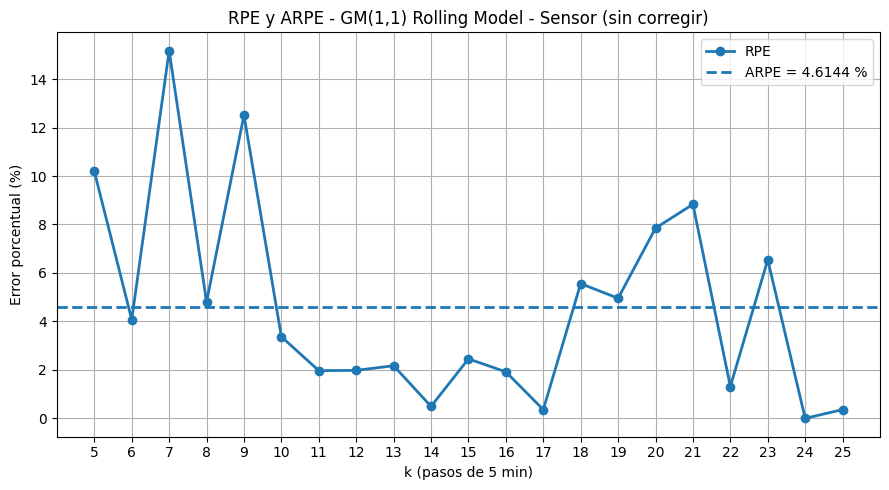

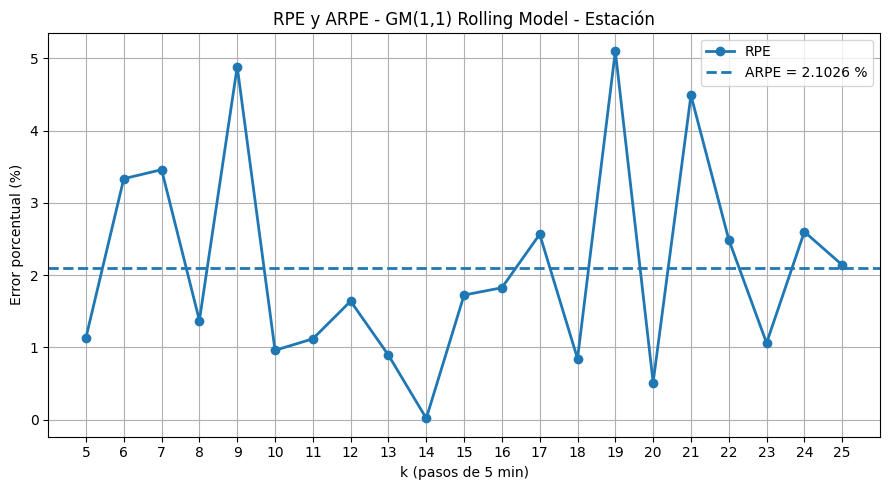

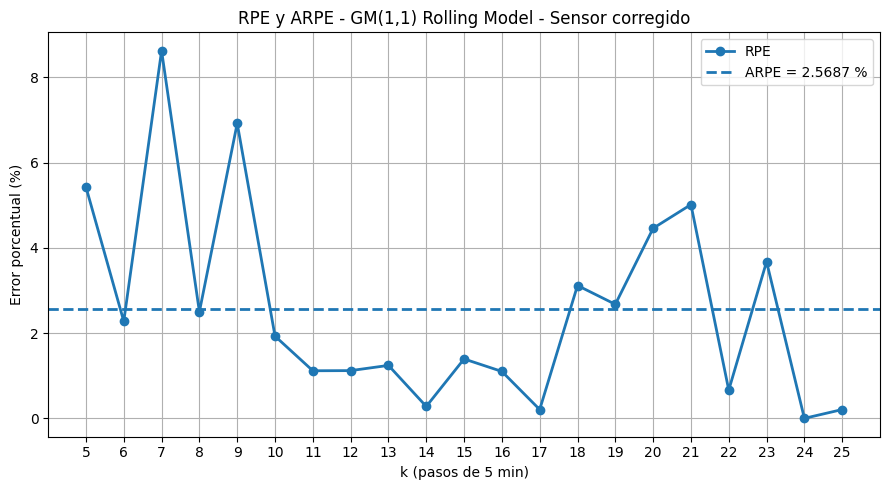

In [ ]:
## ============================================================
# EVALUACIÓN DEL GM(1,1) ROLLING MODEL
# Cálculo de ERROR, RPE y ARPE
# (usa `series`, `ventana` y los diccionarios `series_roll_*`
#  de la celda anterior)
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. ERROR, RPE Y ARPE POR SERIE
# ============================================================

series_eval = {}

for nombre, X0 in series.items():

    # Valores reales que fueron pronosticados (desde el dato ventana+1)
    valores_reales = X0[ventana:]

    # Predicciones del rolling
    predicciones = series_roll_pred[nombre]

    # epsilon(k) = x(k) - x_hat(k)
    error = valores_reales - predicciones

    # RPE(k) = |error(k)| / |x(k)| * 100
    RPE = np.abs(error) / np.abs(valores_reales) * 100

    # ARPE = promedio de todos los RPE
    ARPE = np.mean(RPE)

    # Índices correspondientes a los puntos pronosticados
    k_pred = np.arange(ventana + 1, len(X0) + 1)

    tabla_resultados = pd.DataFrame({
        'k': k_pred,
        'Valor real': valores_reales,
        'Valor predicho': predicciones,
        'Error': error,
        'RPE (%)': RPE
    })

    series_eval[nombre] = {
        "k_pred": k_pred,
        "error": error,
        "RPE": RPE,
        "ARPE": ARPE,
        "tabla": tabla_resultados,
    }


# ============================================================
# 2. MOSTRAR RESULTADOS
# ============================================================

for nombre in series:
    ev = series_eval[nombre]

    print("========================================")
    print(f"EVALUACIÓN DEL GM(1,1) ROLLING MODEL - {nombre}")
    print("========================================")

    print("\nValores reales:")
    print(series_roll_real[nombre])

    print("\nValores predichos:")
    print(series_roll_pred[nombre])

    print("\nError:")
    print(ev["error"])

    print("\nRPE (%):")
    print(ev["RPE"])

    print("\n----------------------------------------")
    print(f"ARPE = {ev['ARPE']:.4f} %")
    print("----------------------------------------")

    print("\nTABLA DE RESULTADOS")
    print(ev["tabla"].to_string(index=False))
    print("\n")


# ============================================================
# 3. RESUMEN COMPARATIVO
# ============================================================

print("========================================")
print("RESUMEN ARPE POR SERIE")
print("========================================")
for nombre in series:
    print(f"  {nombre}: {series_eval[nombre]['ARPE']:.4f} %")


# ============================================================
# 4. GRÁFICA DEL RPE (una por serie)
# ============================================================

for nombre in series:
    ev = series_eval[nombre]

    plt.figure(figsize=(9, 5))

    plt.plot(ev["k_pred"], ev["RPE"],
             marker='o', linewidth=2, label='RPE')

    # Línea correspondiente al ARPE
    plt.axhline(y=ev["ARPE"],
                linestyle='--', linewidth=2,
                label=f'ARPE = {ev["ARPE"]:.4f} %')

    plt.xlabel('k (pasos de 5 min)')
    plt.ylabel('Error porcentual (%)')
    plt.title(f'RPE y ARPE - GM(1,1) Rolling Model - {nombre}')

    plt.xticks(ev["k_pred"])
    plt.grid(True)
    plt.legend()
    plt.tight_layout()

    plt.show()